/home/eduser/pycharm/meta-neural-sci/meta-neural-sci_mvp/lib/torch_functions.py:236: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  theta = torch.tensor(n * w_rad, device=device)


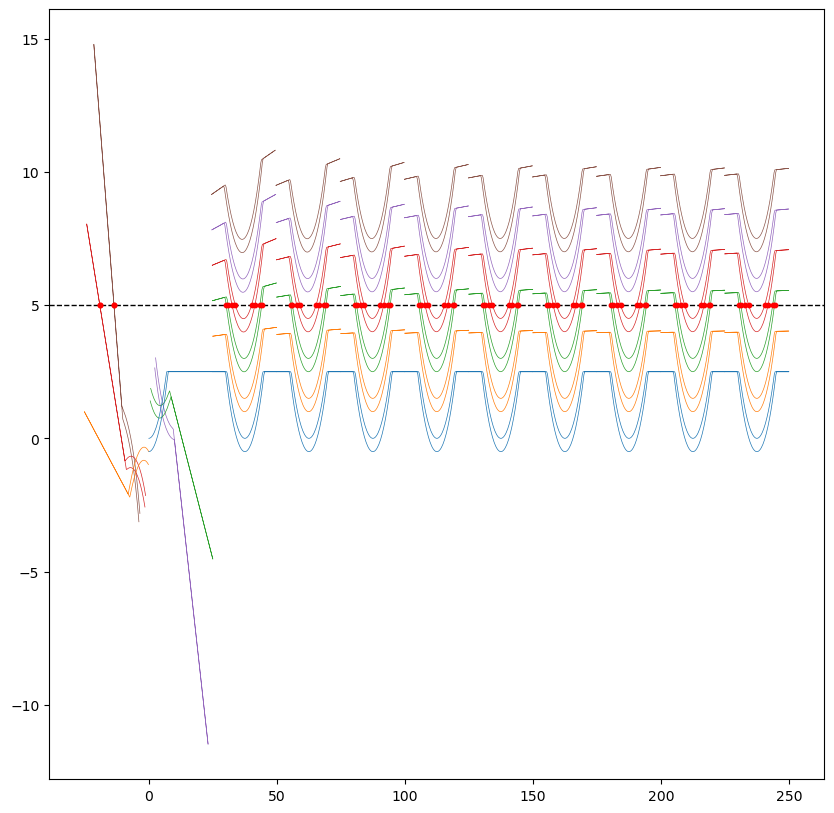

In [1]:
# Настройка проекта
import matplotlib.pyplot as plt
import meep as mp
# import meep.adjoint as mpa
import conf
import torch
from lib import adjoint as mpa
from lib import torch_functions as tf
from lib import numpy_functions as nf
from lib import my_gui, my_decoders, my_sources
from autograd import numpy as npa
import numpy as np

mp.verbosity(0) # decrease amount of output
"""
Base
"""
# Для первичной инициализации params может принимать любые значения.
rt_tf = tf.calculate_radii_step(D=conf.aperture, orders=conf.orders)
rt_np = nf.calculate_radii_step(D=conf.aperture, orders=conf.orders)
d_rt_np, mid_rt_np = nf.get_drt_midrt(rt_np, conf.orders)
# инициализируем генератор
gen_reslution = nf.AdaptiveResolution(
    drt=d_rt_np,
    x_dim=conf.x_dim,
    h_dim= conf.h_dim,
)
# получаем список разрешений
resolutions_objs = gen_reslution.generate()
resolutions_tuples = [(r.w, r.h) for r in resolutions_objs]
a_params = torch.full((conf.orders,), 10.0, dtype=torch.float64)
h_params = torch.full((conf.orders,), 1.0, dtype=torch.float64)
list_x0 = tf.material_grid_weight_2d_rotate(a_params, h_params, conf.at_hei, conf.orders, conf.stack, rt_tf, resolutions_tuples, Q = conf.Q, w = conf.w, LIMIT_SHAPE= conf.LIMIT_SHAPE, smooth = False, beta = 40.0, plot = True)